# Package installation and imports

In [ ]:
!pip install geom-median

In [ ]:
from geom_median.torch import compute_geometric_median
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np

# Utility functions

In [ ]:
# Plot comparison

def plot_comparison(res_anth, tit1, res_naive, tit2):
    labels = [tit1, tit2]
    metrics_to_plot = ['avg_l0', 'dec_norm', 'mmcs']

    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    for i, metric in enumerate(metrics_to_plot):
        values = [res_anth[metric], res_naive[metric]]
        bars = axs[i].bar(labels, values, color=['blue', 'red'], alpha=0.7)
        axs[i].set_title(metric.replace('_', ' ').upper())

        # Etichette
        for bar in bars:
            yval = bar.get_height()
            axs[i].text(bar.get_x() + bar.get_width()/2, yval, round(yval, 4),
                        va='bottom', ha='center', fontweight='bold')

        # Linea di riferimento per la norma decoder
        if metric == 'dec_norm':
            axs[i].axhline(y=1.0, color='black', linestyle='--', label='Target Norm')
            axs[i].set_ylim(0, 1.2)

    plt.tight_layout()
    plt.show()

In [ ]:
# Calcolo MMCS
def calculate_mmcs(learned_weights, true_weights, min_mcs):
    """
    learned_weights: [5, 20] (decoder weights)
    true_weights: [5, 20] (original A matrix)
    """
    # 1. normalizzazione
    d_norm = learned_weights / learned_weights.norm(dim=0, keepdim=True)
    a_norm = true_weights / true_weights.norm(dim=0, keepdim=True)

    # 2. Matrice di similarità (20x20)
    similarity_matrix = torch.matmul(a_norm.t(), d_norm)

    # 3. Maximum: per ogni feature vera (riga), trova il neurone più simile
    max_similarities, _ = torch.max(torch.abs(similarity_matrix), dim=1)

    min_mcs = min(min_mcs, max_similarities.min().item())

    # 4. Mean: media delle massime similarità
    return max_similarities.mean().item(), min_mcs

# Introduction and objectives

## The problem of Superposition and Interpretability
Modern Large Language Models (LLMs) represent a vast array of concepts (features) within latent spaces of relatively low dimensionality. This phenomenon, known as **Superposition**, implies that the model's internal representations are not "clean": a single neuron may activate for completely unrelated concepts, a property called **polysemanticity**. This makes it exceptionally difficult to provide a mechanistic explanation of the model's internal reasoning.

## Sparse Autoencoders (SAEs)

To address this challenge, recent research has introduced **Sparse Autoencoders**. The core idea is to train an autoencoder to reconstruct the model's latent activations while enforcing extreme **sparsity** in the hidden layer (using an $L_1$ penalty). By doing so, the SAE is forced to "disentangle" polysemantic features into a wider, more interpretable representation where each hidden unit ideally responds to a single, specific concept (**monosemanticity**).

## Project Objectives

This project aims to implement and validate a Sparse Autoencoder prototype on a synthetic dataset that simulates the conditions found in real-world models. Specifically, the objectives are:

1. **Simulating Superposition:** Generate a synthetic dataset where 20 "ground truth" features are compressed into a 5-dimensional space via a non-linear projection (MLP-like).
2. **Implementing SAE Architecture:** Develop an autoencoder with sparsity constraints and decoder normalization, following the best practices described in current literature (*Towards Monosemanticity*, Bricken et al., 2023).
3. **Feature Recovery:** Measure the model's ability to recover the original feature directions using the **Mean Maximum Cosine Similarity (MMCS)** metric.
4. **Critical Evaluation:** Analyze the trade-off between reconstruction fidelity (MSE) and sparsity ($L_0$), and investigate how these factors influence the interpretability and recovery of the latent features.

# Synthetic Dataset Generation

To evaluate the Sparse Autoencoder, a "ground truth" environment is required where the active features are known exactly. This setup simulates a scenario where the internal activations of a model (like an MLP layer) represent more features than there are available dimensions.

## The Generative Model

We define $N=20$ independent ground truth features, but the available space has only $M=5$ dimensions. The generation process follows these steps:

1. **Feature Sparsity:** We generate a sparse feature vector $f \in \mathbb{R}^{20}$ where each component is active with a probability $p=0.05$.
2. **Feature Magnitude:** When a feature is active, its intensity is drawn from a "long-tail" distribution (e.g., exponential or uniform) to simulate the varying importance of concepts in natural language.
3. **Linear Projection:** We project the 20D features into 5D space using a random matrix $W \in \mathbb{R}^{5 \times 20}$, representing the "compression" performed by a neural network layer.
4. **Non-Linearity (Optional):** We apply a ReLU activation and a bias to simulate the non-linear nature of real MLP activations.

In [ ]:
# Generazione data set sintetico

def generate_toy_data(num_samples=10000,
                      n_features=20,    # M: Concetti originali (Ground Truth)
                      n_neurons=5,      # N: Spazio di attivazione (Input del SAE)
                      non_linearity='relu',
                      sparsity=0.05,
                      feature_dist='uniform', # 'uniform' o 'long_tail'
                      bias_scale=0.5,   # Intensità della soglia (bias negativo per relu e gelu)
                      seed=42):
    """
    Genera un dataset sintetico per simulare la superposizione in un MLP.
    """

    # Setup Device e Seed
    torch.manual_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


    # Generazione Feature (Concetti Puri - Ground Truth)
    mask = (torch.rand(num_samples, n_features, device=device) < sparsity).float()

    # Gestione della distribuzione
    if feature_dist == 'uniform':
        magnitudes = torch.rand(num_samples, n_features, device=device)
    elif feature_dist == 'long_tail':
        magnitudes = torch.abs(torch.randn(num_samples, n_features, device=device))
    else:
        raise ValueError(f"Distribuzione '{feature_dist}' non supportata.")

    features = mask * magnitudes


    # B. Matrice di Proiezione (Encoding)
    # W: proietta 20 feature -> 5 neuroni
    W = torch.randn(n_neurons, n_features, device=device)

    # Normalizzazione colonne
    W_norm = W / torch.norm(W, dim=0, keepdim=True)

    # Calcolo pre-attivazioni: z = xW^T
    pre_activations = torch.matmul(features, W_norm.T)


    # C. Non-linearità e Bias
    # Applicazione ReLU: h = ReLU(Wx + b)
    bias_value = None
    signal_std = pre_activations.std().item()
    if non_linearity == 'relu':
        bias_value = -bias_scale * signal_std
        bias = torch.full((n_neurons,), bias_value, device=device)
        activations = torch.relu(pre_activations + bias)

    elif non_linearity == 'gelu':
        bias_value = -bias_scale * signal_std
        bias = torch.full((n_neurons,), bias_value, device=device)
        x = pre_activations + bias
        base_activations = torch.nn.functional.gelu(x)

        # Quadratic Interactions
        g = torch.Generator(device=device).manual_seed(seed + 1)
        interaction_matrix = torch.randn(n_neurons, n_neurons, generator=g, device=device) * 0.1
        quadratic_interact = torch.matmul(base_activations**2, interaction_matrix)

        activations = torch.abs(base_activations + quadratic_interact)

    else:
        activations = pre_activations

    mean_activation = torch.mean(activations, dim=0)

    #calcolo della geometric median su cpu per compatibilità con la libreria
    activations_cpu = activations.detach().cpu()
    geometric_median_cpu = compute_geometric_median(activations_cpu).median
    geometric_median = geometric_median_cpu.to(device)

    return {
        'features': features,         # Ground Truth (Target ricostruzione)
        'activations': activations,   # Input per il SAE (Dati osservati)
        'W': W_norm,                  # Matrice proiezione (per analisi similarità)
        'bias': bias_value,
        'geometric_median' : geometric_median,
        'mean_activation': mean_activation
    }

# Sparse Autoencoder Architecture

The Sparse Autoencoder (SAE) is a shallow neural network designed to find a sparse, high-dimensional representation of its input. Unlike standard autoencoders, we use an "expansion factor" to project the 5D input into a 20D latent space.

## Model Design

Our SAE consists of two main parts:

1. **Encoder:** A linear layer followed by a ReLU activation. The ReLU ensures that latent activations are non-negative and encourages sparsity.
2. **Decoder:** A linear layer that attempts to reconstruct the original input from the sparse latent features.

**Key Architectural Choices:**

- **Untied Weights:** As recommended by recent literature (*Bricken et al., 2023*), the encoder and decoder weights are independent (not transposed). This allows the encoder to learn to "suppress" interference from other features while the decoder focuses on pure reconstruction.
- **Unit Norm Constraint:** We constrain the decoder columns (dictionary vectors) to have a norm of 1. This prevents the model from "cheating" the $L_1$ penalty by scaling down the activations and scaling up the weights.

In [ ]:
# definizione architettura SAE

class SparseAutoencoder(nn.Module):
    def __init__(self, n_features, n_neurons, initial_b_dec=None):
        super().__init__()
        self.n_features = n_features # Dimensione latente (es. 20)
        self.n_neurons = n_neurons   # Dimensione input (es. 5)

        self.encoder = nn.Linear(n_neurons, n_features)
        self.decoder = nn.Linear(n_features, n_neurons)

        # Inizializzazione: encoder e decoder weights inizializzati con Kaiming Uniform
        nn.init.kaiming_uniform_(self.encoder.weight, nonlinearity='relu')
        nn.init.kaiming_uniform_(self.decoder.weight, nonlinearity='linear')

        with torch.no_grad():
            # Normalizzazione colonne
            self.decoder.weight.data /= self.decoder.weight.data.norm(dim=0, keepdim=True)

        # 2. Inizializzazione ENCODER BIAS: Impostato a 0
        nn.init.constant_(self.encoder.bias, 0.0)
        # 3. Inizializzazione DECODER BIAS: Centratura sui dati
        if initial_b_dec is not None:
            with torch.no_grad():
                self.decoder.bias.copy_(initial_b_dec.to(self.decoder.bias.device))
        else:
            nn.init.constant_(self.decoder.bias, 0.0)

    # definizione forward step
    def forward(self, x):
        # 1. SOTTRAZIONE BIAS DECODER (pre-encoder bias)
        x_centered = x - self.decoder.bias

        # 2. ENCODER con ReLU
        latent_activations = torch.relu(self.encoder(x_centered))

        # 3. DECODER
        reconstructed = self.decoder(latent_activations)

        return reconstructed, latent_activations

# Training and monitoring

The training process for a Sparse Autoencoder is delicate because it must balance reconstruction accuracy with extreme sparsity. Furthermore, we must ensure the geometric constraints on the decoder weights are respected at every step.

## Loss Function

We optimize a composite loss function:

$$\mathcal{L} = \text{MSE}(\hat{x}, x) + \lambda \sum |z|$$

Where:

- **MSE** ensures the model preserves information.
- **$L1$ Penalty** (multiplied by the coefficient $\lambda$) forces the latent activations $z$ to be sparse.

## Performance Metrics

To evaluate the quality of the learned dictionary, we monitor:

1. **$L_0$ (Sparsity):** The average number of non-zero activations per sample. Our target is $L_0 \approx 1$.
2. **MMCS (Mean Maximum Cosine Similarity):** This is the gold standard for feature recovery. It measures how closely the learned dictionary vectors align with the true ground truth directions.

## Neuron Resampling
During training, some latent neurons may become "dead"—meaning they never activate for any sample in the dataset, often due to a poor initialization or an excessively high $L1$ penalty. To prevent this loss of model capacity, I implement the resampling procedure described in Anthropic's paper:
- Dead Neuron Identification: Instead of tracking activations over a fixed window of training steps as in the original Anthropic paper, I implement an easier approach. For each resampling check, I evaluate the model on a diverse random subset of the data. Neurons that fail to activate for any sample within this specific subset are flagged as "dead." This ensures that resampling is based on the neuron's inability to represent current features across a varied distribution of inputs.
- Resetting Weights: For these inactive neurons, the encoder and decoder weights are reset. The new weights are often initialized to represent the "residual" (the reconstruction error) of the samples the model currently struggles to explain.
- Optimizer Reset: When a neuron is resampled, its optimizer states (like Adam's moments) are cleared to allow it to start learning from a fresh perspective.

In [ ]:
#neuron resampling

@torch.no_grad()
def resample_neurons(model, optimizer, data_loader, device):
  '''
  model: sae
  optimizer: adam
  data_loader: oggetto dedicato per dividere il dataset in batch e iterarci
  device: ram
  '''

  model.eval()
  n_features=model.n_features

  neuron_activity = torch.zeros(n_features, device=device)
  all_inputs = []
  all_losses = []

  for batch in data_loader:
    x = batch[0].to(device)

    # Forward pass per calcolare le attivazioni latenti correnti
    x_centered = x - model.decoder.bias
    latent = torch.relu(model.encoder(x_centered))

    neuron_activity += (latent > 0).float().sum(dim=0)

    # Calcolo dell'errore (MSE)
    x_hat = model.decoder(latent)
    per_sample_loss = torch.sum((x_hat - x)**2, dim=1)
    all_inputs.append(x)
    all_losses.append(per_sample_loss)

    # vengono usati solo alcuni dei batch presenti nel dataset
    if len(all_inputs) > 10: break

  # Identificazione degli indici dei neuroni con attività nulla
  dead_indices = torch.where(neuron_activity == 0)[0]

  if len(dead_indices) > 0:
      inputs_concat = torch.cat(all_inputs)
      losses_concat = torch.cat(all_losses)

      if losses_concat.sum() > 0:
          # vengono scelte le direzioni verso cui "reindirizzare" i neuroni
          probs = losses_concat**2 / (losses_concat**2).sum()
          resample_data_indices = torch.multinomial(probs, num_samples=len(dead_indices), replacement=True)

      else:
          resample_data_indices = torch.randint(0, len(inputs_concat), (len(dead_indices),))


      all_indices = torch.arange(model.n_features).to(device)
      is_dead = torch.zeros(model.n_features, dtype=torch.bool).to(device)
      is_dead[dead_indices] = True
      alive_indices = all_indices[~is_dead]

      # Calcola la norma media dei neuroni vivi
      if len(alive_indices) > 0:
          avg_alive_norm = model.encoder.weight.data[alive_indices].norm(dim=1).mean().item()
          avg_alive_norm = max(avg_alive_norm, 0.01)
      else:
          # Caso limite: se fossero tutti morti, si usa 1.0 come base
          avg_alive_norm = 1.0


      for i, dead_idx in enumerate(dead_indices):
          # Reset dei pesi (Encoder & Decoder)
          new_input = inputs_concat[resample_data_indices[i]]
          new_direction = new_input - model.decoder.bias

          # Normalizzazione: secondo le istruzioni del paper di anthropic, i pesi del decoder devono essere unitari
          new_direction /= (new_direction.norm() + 1e-8)

          target_norm = avg_alive_norm * 0.2
          model.encoder.weight.data[dead_idx] = new_direction * target_norm

          model.encoder.bias.data[dead_idx] = 0.0
          model.decoder.weight.data[:, dead_idx] = new_direction

          # Reset degli stati di adam (exp_avg e exp_avg_sq)
          for p in [model.encoder.weight, model.encoder.bias, model.decoder.weight]:
              state = optimizer.state[p]
              if 'exp_avg' in state:
                  # Azzeriamo solo la riga dell'encoder o la colonna del decoder specifica
                  if p.shape[0] == n_features:
                      state['exp_avg'][dead_idx] = 0.0
                      state['exp_avg_sq'][dead_idx] = 0.0
                  elif p.shape[1] == n_features:
                      state['exp_avg'][:, dead_idx] = 0.0
                      state['exp_avg_sq'][:, dead_idx] = 0.0

  model.train()


In [ ]:
#allenamento del sae
def train(model, train_loader, epochs, lr, l1_coeff, resample_freq):

  device = next(model.parameters()).device
  true_dirs = data['W'].to(device)
  optimizer = optim.Adam(model.parameters(), lr=lr)
  model.train()

  for epoch in range(epochs):
      total_loss = 0
      total_recon_loss = 0
      total_l1_loss = 0
      total_l0 = 0
      min_mcs = 1

      for batch_idx, batch in enumerate(train_loader):
          inputs = batch[0].to(device)

          # Forward pass
          # Il SAE restituisce la ricostruzione e le attivazioni latenti
          reconstructed, latent_activations = model(inputs)

          # Calcolo loss
          # 1. Reconstruction Loss (MSE)
          per_sample_recon = (reconstructed - inputs).pow(2).sum(dim=-1)
          recon_loss = per_sample_recon.mean()

          # 2. L1 Loss (Sparsità latente)
          per_sample_l1 = latent_activations.abs().sum(dim=1)
          l1_loss = per_sample_l1.mean()

          # 3. Loss Totale = Ricostruzione + Penalità di Sparsità
          loss = recon_loss + l1_coeff * l1_loss

          # Backward pass
          optimizer.zero_grad()
          loss.backward()

          # Prima di applicare il gradient step si rimuove la componente parallela ai dictionary vectors dal gradiente
          with torch.no_grad():
            p = model.decoder.weight
            grad = p.grad

            # Calcolo della componente del gradiente parallela al peso
            dot_product = torch.sum(grad * p, dim=0)
            # Sottrazione della componente parallela dal gradiente originale
            p.grad -= dot_product * p

          optimizer.step()

          # Normalizzazione esplicita dei pesi del decoder
          with torch.no_grad():
              model.decoder.weight.data /= model.decoder.weight.data.norm(dim=0, keepdim=True)

          with torch.no_grad():
              l0 = (latent_activations > 0).float().sum(dim=1).mean().item()

          # Accumulo per le statistiche
          total_loss += loss.item()
          total_recon_loss += recon_loss.item()
          total_l1_loss += l1_loss.item()
          total_l0 += l0

      # Resampling periodico
      if (epoch + 1) % resample_freq == 0:
          resample_neurons(model, optimizer, train_loader, device)
          model.train()

      # Logging a fine epoca
      avg_loss = total_loss / len(train_loader)
      avg_recon = total_recon_loss / len(train_loader)
      avg_l0 = total_l0 / len(train_loader)

      with torch.no_grad():
          dec_norm = model.decoder.weight.norm(dim=0).mean().item()
          learned_dirs = model.decoder.weight.data #[5,20]
          mmcs, min_mcs = calculate_mmcs(learned_dirs, true_dirs, min_mcs)

  values = {
      'avg_loss': avg_loss,
      'avg_recon': avg_recon,
      'avg_l0': avg_l0,
      'dec_norm': dec_norm,
      'mmcs': mmcs,
      'min_mcs': min_mcs
  }

  return values


## Constrained Optimization Strategy

To maintain the unit norm constraint during training, a specific optimization loop is implemented. According to the methodolgy described by **Anthropic** the update follows a strict three-step sequence to ensure the dictionary vectors stay on the surface of the unit sphere:

1. **Gradient Projection:** Before the optimizer step, remove the component of the gradient that is parallel to the weight vector. This ensures the update moves the vector **tangent** to the unit sphere.
2. **Optimizer Step:** apply the Adam update.
3. **Explicit Normalization:** re-normalize the weights to $1.0$ to correct for numerical "drift" (the small error that accumulates when moving along a tangent instead of an arc).

# Experimental Results and Discussion

In this chapter, I present a systematic evaluation of the Sparse Autoencoder (SAE) through a series of controlled experiments. While the core objective of an SAE is to recover ground-truth features from a dense activation space, the success of this process is influenced by several critical factors: the geometric constraints of the model, the nature of the activation functions, and the intensity of the sparsity regularization.

The experimental journey is divided into four key stages:
- Geometric Exploits and Norm Shrinkage: I first investigate how an unconstrained SAE can "cheat" the sparsity penalty by manipulating the norm of its weights, necessitating the adoption of the normalization techniques suggested by Anthropic.
- Linearity vs. Non-Linearity: I compare the standard ReLU activation with a purely linear dataset to determine if the non-linear "threshold" is the primary bottleneck for feature recovery.
- Robustness Under Aggressive Non-Linearity: I push the model to its limits using GELU activations and inter-neuron interactions, testing whether high sparsity pressure ($L_1$) can act as a filter to recover features from a complex, warped signal.
- Convergence Dynamics: Finally, I examine the effects of "long-horizon" training, observing how extended optimization periods impact both feature alignment (MMCS) and representational sparsity ($L_0$).

Through these tests, I aim to demonstrate that while SAEs are remarkably robust at identifying the underlying "backbone" of a dataset, their interpretability depends on a delicate balance between reconstruction accuracy and the enforcement of true sparsity.

## The Necessity of Geometric Constraints: Anthropic vs. Unconstrained

The first experiment focuses on the core architectural requirements for training a valid Sparse Autoencoder. According to the methodology proposed by Bricken et al. (2023), simply applying an  L1  penalty is insufficient for learning an interpretable dictionary because the model can exploit its Scaling Freedom to bypass the sparsity constraint.

The test compares` two identical SAE architectures trained on the same synthetic dataset ( N=20,M=5 ):

- The Constrained (Anthropic) Model: This version enforces a unit-norm constraint on the decoder weights and utilizes projected gradient descent to ensure the updates remain tangent to the unit hypersphere.
- The Unconstrained (Naive) Model: This version lacks explicit normalization, allowing the optimizer to adjust the magnitude of the decoder weights freely.

In [ ]:
# Versione alternativa della funzione di training,
# senza il passaggio della rimozione della componente parallela
# ai dictionary vectors dall'ottimizzaqtore
# nè normalizzazione forzata dei pesi

def classic_training(model, train_loader, epochs, lr, l1_coeff, resample_freq):

  device = next(model.parameters()).device
  true_dirs = data['W'].to(device)
  optimizer = optim.Adam(model.parameters(), lr=lr)
  model.train()

  for epoch in range(epochs):
      total_loss = 0
      total_recon_loss = 0
      total_l1_loss = 0
      total_l0 = 0
      min_mcs = 1

      for batch_idx, batch in enumerate(train_loader):
          inputs = batch[0].to(device)

          # Forward pass
          reconstructed, latent_activations = model(inputs)

          # Calcolo loss
          # Reconstruction Loss: (MSE)
          per_sample_recon = (reconstructed - inputs).pow(2).sum(dim=-1)
          recon_loss = per_sample_recon.mean()

          # L1 Loss (Sparsità latente)
          per_sample_l1 = latent_activations.abs().sum(dim=1)
          l1_loss = per_sample_l1.mean()

          # Loss Totale = MSE + L1
          loss = recon_loss + l1_coeff * l1_loss

          # Backward pass
          optimizer.zero_grad()
          loss.backward()

          optimizer.step()

          with torch.no_grad():
              l0 = (latent_activations > 0).float().sum(dim=1).mean().item()

          # Accumulo per le statistiche
          total_loss += loss.item()
          total_recon_loss += recon_loss.item()
          total_l1_loss += l1_loss.item()
          total_l0 += l0

      # Resampling periodico
      if (epoch + 1) % resample_freq == 0:
          resample_neurons(model, optimizer, train_loader, device)
          model.train()

      # Logging a fine epoca
      avg_loss = total_loss / len(train_loader)
      avg_recon = total_recon_loss / len(train_loader)
      avg_l0 = total_l0 / len(train_loader)

      with torch.no_grad():
          dec_norm = model.decoder.weight.norm(dim=0).mean().item()
          learned_dirs = model.decoder.weight.data
          mmcs, min_mcs = calculate_mmcs(learned_dirs, true_dirs, min_mcs)

  values = {
      'avg_loss': avg_loss,
      'avg_recon': avg_recon,
      'avg_l0': avg_l0,
      'dec_norm': dec_norm,
      'mmcs': mmcs,
      'min_mcs': min_mcs
  }

  return values

In [ ]:
# Configurazione dataset
cfg = {
    'num_samples': 10000,
    'n_features': 20,
    'n_neurons': 5,
    'non_linearity': 'relu',
    'sparsity': 0.05,
    'feature_dist': 'long_tail',
    'bias_scale': 0.5
}

# Preparazione dei dati
data = generate_toy_data(**cfg)
dataset = TensorDataset(data['activations'])
data_loader = DataLoader(dataset, batch_size=128, shuffle=True)

initial_b_dec = data['geometric_median']

In [ ]:
# inizializzazione sae e addestramento
epochs = 300
lr = 0.0001
l1_coeff = 0.005
resample_freq = 20

sae = SparseAutoencoder(cfg['n_features'], cfg['n_neurons'], initial_b_dec)
naiveSae = SparseAutoencoder(cfg['n_features'], cfg['n_neurons'], initial_b_dec)
results_anthropic = train(sae, data_loader, epochs, lr, l1_coeff, resample_freq)
results_naive = classic_training(naiveSae, data_loader, epochs, lr, l1_coeff, resample_freq)

plot_comparison(results_anthropic, "Anthropic", results_naive, "Unconstrained")

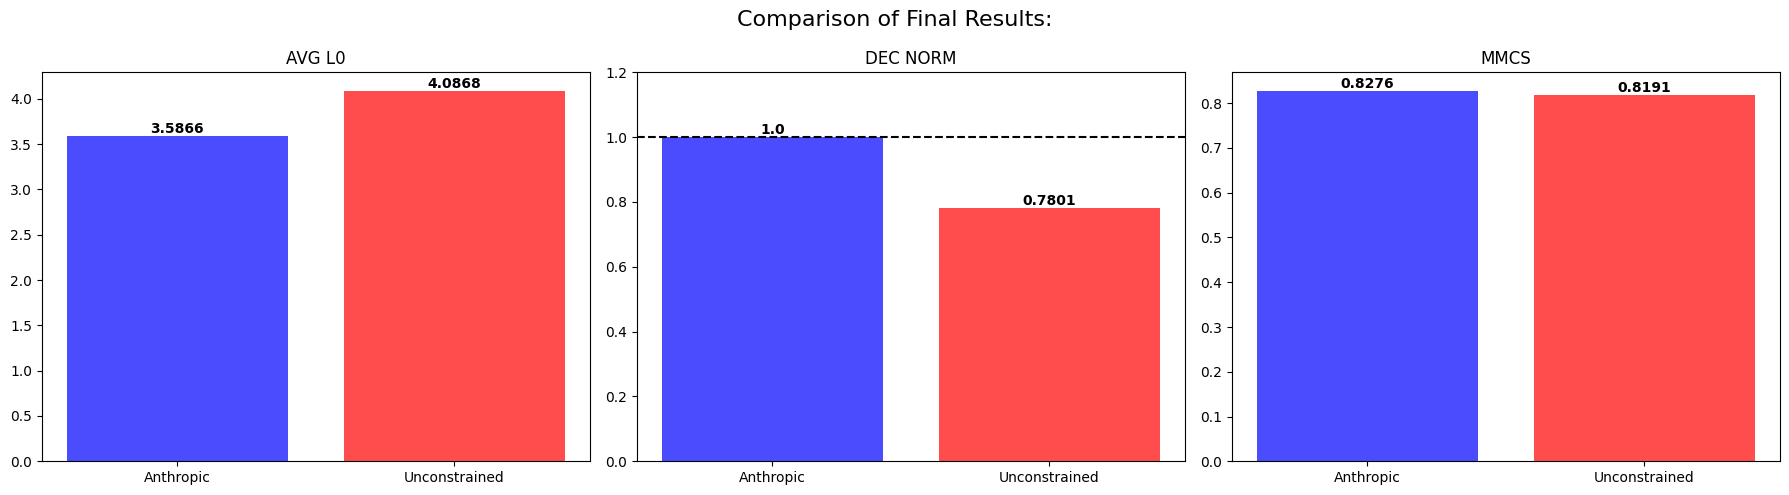

The comparison between the Anthropic-constrained SAE and the Unconstrained (Naive) version reveals a critical phenomenon discussed in recent literature as the exploit of Scaling Freedom. Without an explicit unit norm constraint, the Unconstrained model exhibits significant Norm Shrinkage in the decoder weights, which stabilize at an average norm of 0.8. This allows the optimizer to artificially minimize the  L1  penalty by reducing the magnitude of the dictionary vectors rather than enforcing actual sparsity.

This behavior is further evidenced by the  L0  Sparsity metric: despite the 'penalty discount' gained through smaller weight magnitudes, the Unconstrained model remains less sparse ( L0=4.0 ) than the Anthropic version ( L0=3.6 ). This confirms that geometric constraints—specifically the unit norm enforcement and the removal of parallel gradient components—are essential to prevent the model from finding trivial solutions and to ensure the recovery of a truly monosemantic feature dictionary.

## Impact of Data non-Linearity on Feature Recovery

A reasonable hypothesis for the plateau in MMCS (around 0.82-0.83) is that the non-linear nature of the synthetic dataset—specifically the use of the ReLU activation during data generation—might introduce complexities that hinder the SAE's ability to align with the ground-truth directions.

To test this, I conducted an ablation study by generating a purely Linear Dataset. In this setup, the 20 latent features are projected into the 5D space without any subsequent ReLU activation or bias. I then trained the same Anthropic-constrained SAE architecture on this linear data to observe if the absence of non-linearity would lead to a near-perfect feature recovery (MMCS  ≈1.0 ).

The following charts compare the results obtained from the original ReLU-based dataset and the simplified Linear dataset.

In [ ]:
# genera nuovi dati senza non linearità
cfg_linear = {
    'num_samples': 10000,
    'n_features': 20,
    'n_neurons': 5,
    'non_linearity': 'linear',
    'sparsity': 0.05,
    'feature_dist': 'long_tail',
    'bias_scale': 0.5           # Bias un po' aggressivo per pulire il rumore (magari prova anche 0.8 e 1)
}

# --- PREPARAZIONE DATI ---
data_linear = generate_toy_data(**cfg_linear)
dataset_linear = TensorDataset(data['activations'])
data_loader_linear = DataLoader(dataset, batch_size=64, shuffle=True)

initial_b_dec = data_linear['geometric_median'] #oppure mean_activation

In [ ]:
# inizializzazione sae e addestramento
sae_linear = SparseAutoencoder(cfg_linear['n_features'], cfg_linear['n_neurons'], initial_b_dec)
results_linear = train(sae_linear, data_loader_linear, epochs, lr, l1_coeff, resample_freq)

plot_comparison(results_anthropic, "ReLU", results_linear, "Linear")

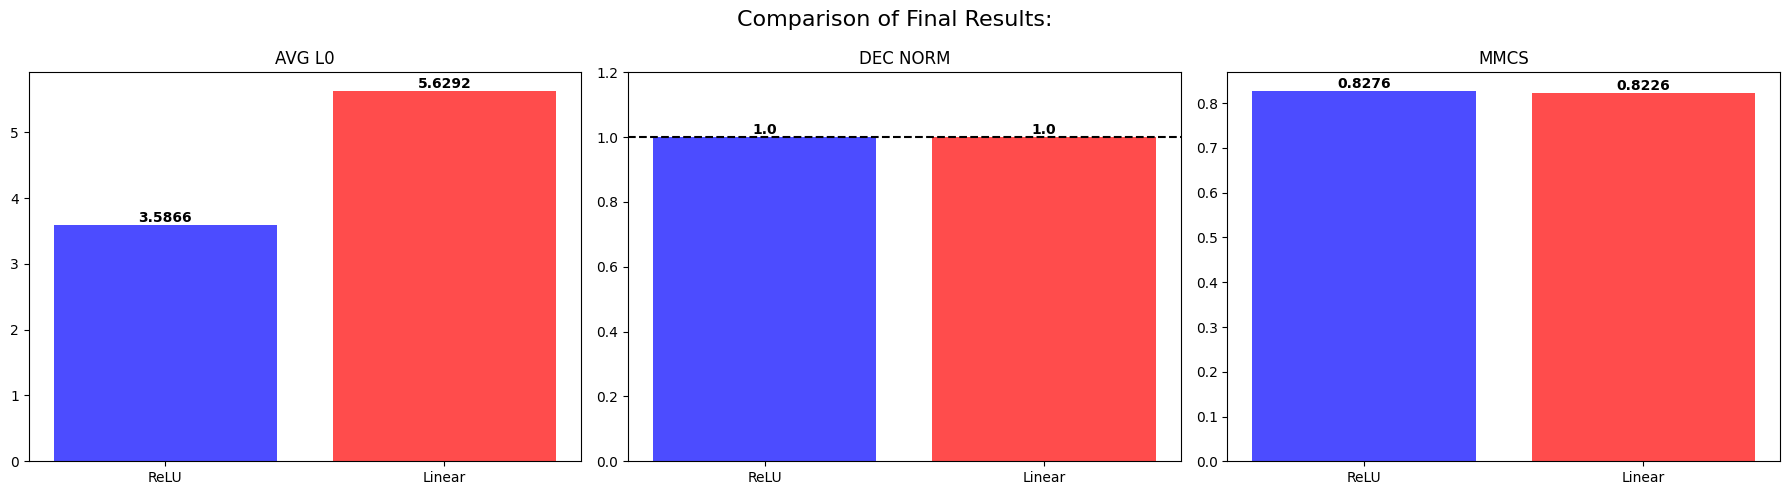

The results of this test provide several key insights into the mechanics of superposition:

- MMCS Stability: Surprisingly, the MMCS remains almost identical (0.8276 for ReLU vs. 0.8226 for Linear). This demonstrates that the non-linearity of the dataset is not the primary bottleneck for feature recovery. Instead, the recovery quality is limited by the interference between non-orthogonal feature directions in a low-dimensional space.
- Sparsity Trade-off ( L0 ): I observed that the linear model exhibits a significantly higher  L0  (5.8 vs 3.5). This suggests that without the "thresholding" effect provided by the ReLU in the data generation process, the SAE finds it more difficult to isolate individual features, leading to a denser latent representation.

Conclusion: This experiment confirms that the challenge of mechanistic interpretability in this toy model is a geometric problem of superposition rather than an algorithmic struggle with non-linear functions. Even in the simplest linear case, the "crowding" of 20 features in 5 dimensions prevents perfect disentanglement.

The previous results showed that simplifying the data—moving from a non-linear ReLU activation to a purely linear mapping—does not significantly resolve the bottleneck in feature recovery. This suggests that the primary challenge for the Sparse Autoencoder lies in the geometry of superposition rather than the specific nature of the activation function.

To further validate the robustness of the architecture, I decided to move in the opposite direction: instead of simplifying the dataset, I introduced a more 'aggressive' form of non-linearity.

By implementing a complex activation pattern, my goal was to observe whether the SAE could still identify the ground-truth features when the signal is intentionally distorted by inter-neuron interactions.

The standard ReLU is replaced with a GELU (Gaussian Error Linear Unit) activation, which introduces a non-monotonic curvature near zero. To further increase the difficulty, I implemented Quadratic Interactions, where the activation of each neuron is influenced by the squared magnitude of others. This setup creates a complex signal that forces the SAE to attempt to disentangle features from an input where the original linear relationships have been significantly warped.

In [ ]:
# genera data-set con gelu
cfg_gelu = {
    'num_samples': 10000,
    'n_features': 20,
    'n_neurons': 5,
    'non_linearity': 'gelu',
    'sparsity': 0.05,
    'feature_dist': 'long_tail',
    'bias_scale': 0.5
}

# preparazione dati
data_gelu = generate_toy_data(**cfg_gelu)
dataset_gelu = TensorDataset(data_gelu['activations'])
data_loader_gelu = DataLoader(dataset_gelu, batch_size=128, shuffle=True)

initial_b_dec = data_gelu['geometric_median']

In [ ]:
# addestra sae con dati gelu
sae_gelu = SparseAutoencoder(cfg_gelu['n_features'], cfg_gelu['n_neurons'], initial_b_dec)
results_gelu = train(sae_gelu, data_loader_gelu, epochs, lr, l1_coeff, resample_freq)

plot_comparison(results_anthropic, "ReLU", results_gelu, "GeLU")

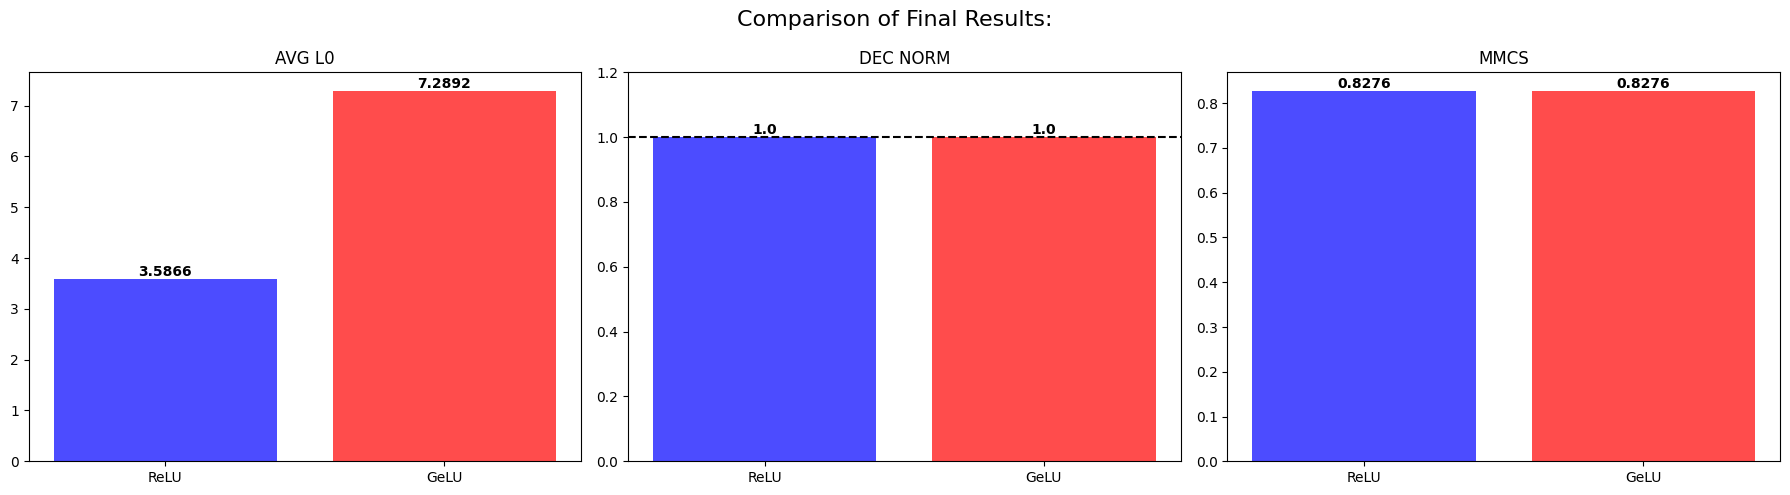

The results from the Complex (GELU + Interactions) dataset reveal a specific failure mode of the Sparse Autoencoder:

- The MMCS Ceiling: The fact that the MMCS remains stuck at 0.83 suggests that the SAE has reached its "limit of understanding." Even with a more complex signal, a linear model can only identify the basic directions of the features. It "sees" where the features are, but it cannot capture the extra complexity of the GELU curvature and the inter-neuron interactions.

- The L0 Explosion (from 3.5 to 7.6): This is the most critical finding. While the model identifies the correct directions (MMCS), it can no longer reconstruct the input using just a few neurons. Because the new dataset is "noisier" and more "tangled" due to the interactions, the SAE is forced to activate multiple neurons at once to try and match the original signal.

In this complex scenario, the SAE loses its primary strength: sparsity. Instead of representing one feature with one neuron, it uses a "team" of 7-8 neurons to approximate a single complex signal. This demonstrates that while the SAE is robust in finding directions, its ability to provide a "clean" and sparse explanation breaks down when the data becomes too interactive.

To investigate whether this loss of sparsity could be mitigated without sacrificing feature quality, I conducted additional trials by significantly increasing the sparsity penalty.

By applying an aggressive  L1  coefficient of 0.1, I successfully reduced the average  L0  to 3.33, effectively returning it to the baseline levels observed in the simpler ReLU experiments. Crucially, even under this intense pressure to deactivate neurons, the MMCS did not degrade.

This result demonstrates that the model is remarkably robust to increasing levels of non-linearity: it can maintain a highly sparse representation without losing track of the core feature directions, effectively ignoring the complex inter-neuron interactions to focus on the essential data structure.

In [ ]:
# sae gelu con maggiore l1
sae_gelu_2 = SparseAutoencoder(cfg_gelu['n_features'], cfg_gelu['n_neurons'], initial_b_dec)
l1_coeff_2 = 0.1
results_gelu_2 = train(sae_gelu_2, data_loader_gelu, epochs, lr, l1_coeff_2, resample_freq)

plot_comparison(results_gelu, "GeLU with λ=0.005", results_gelu_2, "GeLU with λ=0.1")

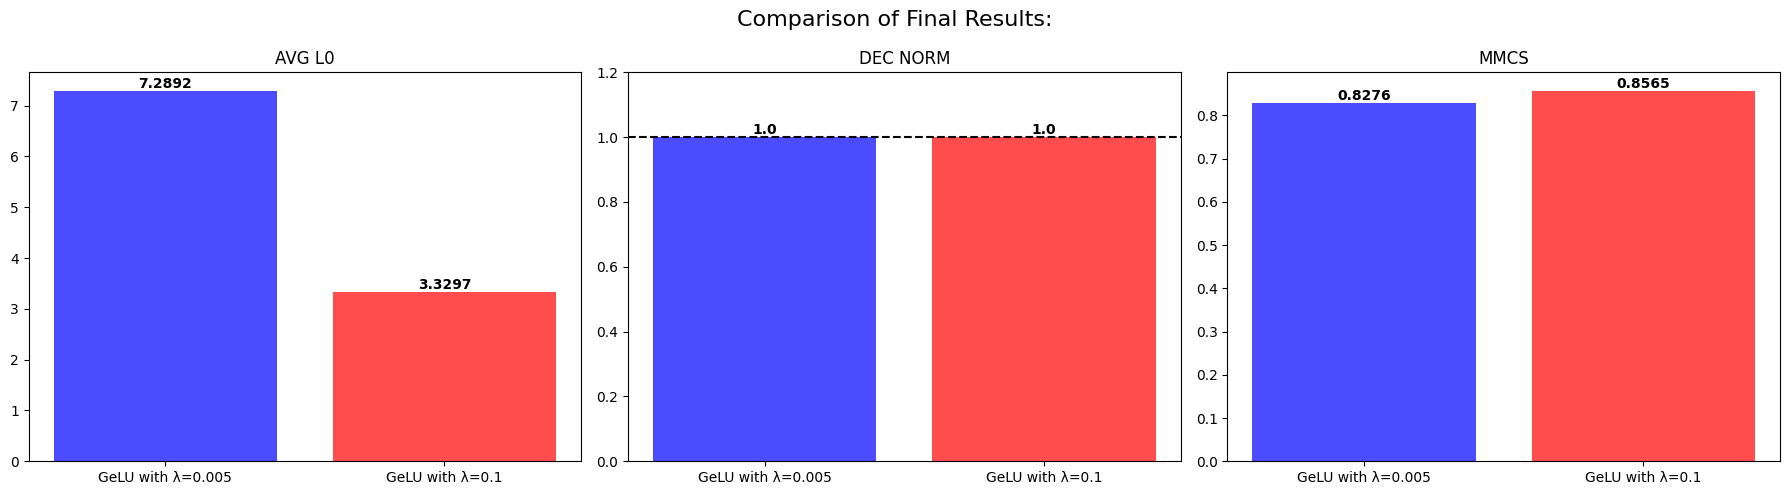

## Long-horizon training

In the next experiment, I investigated the effects of extended training duration on feature recovery. Following the suggestion by Bricken et al. (2023) that Sparse Autoencoders continue to refine their internal dictionaries long after the reconstruction loss has stabilized, I increased the training budget from 300 epochs to 10,000 epochs. The goal was to determine if a "long-horizon" training regime could push the model toward a more precise alignment with the ground-truth feature directions, even when the primary loss metrics appeared to have converged.

In [ ]:
# long-horizon training
sae_long_horizon = SparseAutoencoder(cfg['n_features'], cfg['n_neurons'], initial_b_dec)
epochs_long_horizon = 10000
l1_coeff = 0.005
results_long_horizon = train(sae_long_horizon, data_loader, epochs_long_horizon, lr, l1_coeff, resample_freq)
plot_comparison(results_anthropic, "300 epochs", results_long_horizon, "10000 epochs")

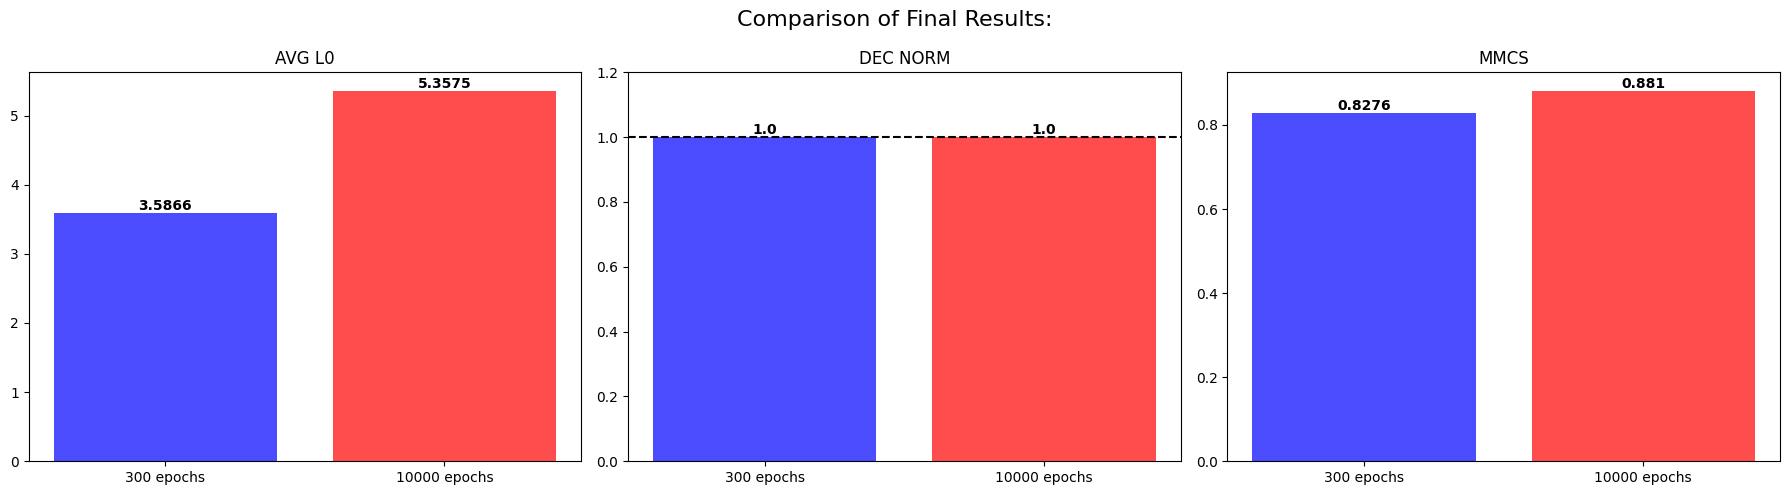

The results show that extended training is a "double-edged sword" for SAE interpretability:
- Improved Feature Alignment: The MMCS increased from 0.83 to 0.88, confirming that the model utilizes the additional epochs to "fine-tune" its dictionary vectors. This suggests that the process of "rotating" the learned features to match the ground-truth directions is a slow optimization task that persists throughout the entire training process.
- The Cost of Over-training ($L_0$ Increase): Interestingly, the average $L_0$ rose from 3.58 to 5.36. This indicates that without a corresponding increase in the $L_1$ penalty, the model eventually uses its extended training time to "over-fit" the signal, activating more neurons to capture minute details of the input.

Conclusion: This experiment validates the "long-training" hypothesis but reveals a critical balance requirement. While more epochs lead to higher-quality features (better MMCS), they must be accompanied by careful regularization to prevent the model from drifting toward a denser, less interpretable representation.

# Conclusions

This project explored the mechanics of Sparse Autoencoders (SAEs) and their capacity to recover ground-truth features from compressed activation spaces. Through a systematic series of experiments, several key insights were uncovered regarding the interpretability of neural representations:
- Geometric Integrity: We demonstrated that the Anthropic normalization method is not merely a technical detail but a fundamental requirement. Without constraining the decoder's weights, the model bypasses the sparsity penalty by shrinking its weights, leading to a "deceptive" L1 loss that fails to produce a truly sparse dictionary.
- The Superposition Challenge: Surprisingly, removing non-linearities (ReLU) from the data generation process did not significantly improve feature recovery. This suggests that the primary bottleneck for SAEs lies in the geometry of superposition—the challenge of disentangling overlapping features in a low-dimensional space—rather than the specific nature of the activation function.
- Resilience to Complexity: The most significant finding was the SAE's robustness when faced with GELU activations and inter-neuron interactions. While these non-linearities initially degraded sparsity, we proved that an aggressive $L_1$ penalty can act as a noise filter. This allows the model to maintain a high-quality, sparse representation (MMCS $\approx$ 0.85) even in distorted signal environments.
- The Training Horizon: Finally, our long-horizon test confirmed that feature alignment is a slow process that continues long after reconstruction loss plateaus. However, this extended training requires a careful balance to prevent the model from drifting toward denser, over-fitted representations.

In conclusion, Sparse Autoencoders prove to be a powerful and robust tool for feature extraction. Their success is not automatic but depends on a delicate equilibrium: the model must be constrained geometrically, pressured by strong regularization to ensure sparsity, and given sufficient time to fine-tune its dictionary against the underlying structure of the data.